<a href="https://colab.research.google.com/github/prantiqueroy/dhaka-air-enforcement/blob/main/notebooks/05_calibration.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

RAW = "https://raw.githubusercontent.com/prantiqueroy/dhaka-air-enforcement/main/data/"
d = pd.read_csv(RAW + "dhaka_daily_adjusted.csv", index_col=0, parse_dates=True)
ne = pd.read_csv(RAW + "natural_experiments.csv")
ne["start_date"] = pd.to_datetime(ne["start_date"], format="%d %b %Y")

# Bangladesh celebrated these a day after the calendar date (confirmed by me, 27 Oct 2026)
moon_fix = {"Eid ul-Fitr 2016": "2016-07-07", "Eid ul-Fitr 2018": "2018-06-16", "Eid ul-Fitr 2024": "2024-04-11"}
for event, day in moon_fix.items():
    ne.loc[ne["event"] == event, "start_date"] = pd.Timestamp(day)

eids = ne[ne["event"].str.startswith("Eid") & (ne["start_date"] < "2025-02-22")].copy()
print("Days of data:", len(d), "| Eids to test:", len(eids))

Days of data: 2478 | Eids to test: 18


In [2]:
# "During" = 1 day before Eid to 3 days after.
# "Normal" = 8–30 days before plus 10–30 days after (skipping the travel days on either side).
# Effect = average weather-adjusted PM2.5 during, minus average on normal days.
def effect(day, during=(-1, 3), before=(-30, -8), after=(10, 30)):
    s = d["adjusted_pct"]
    window = lambda a, b: s.loc[day + pd.Timedelta(days=a): day + pd.Timedelta(days=b)]
    dur = window(*during)
    normal = pd.concat([window(*before), window(*after)])
    if len(dur) < 3 or len(normal) < 15:      # not enough data -> skip
        return np.nan
    return dur.mean() - normal.mean()

eids["effect"] = [round(effect(day), 1) for day in eids["start_date"]]
print(eids[["event", "start_date", "effect"]].to_string(index=False))
tested = eids.dropna(subset=["effect"])
print("\nEids with enough data:", len(tested))
print("Average Eid effect:", round(tested["effect"].mean(), 1), "%")

           event start_date  effect
Eid ul-Fitr 2016 2016-07-07   -29.6
Eid ul-Adha 2016 2016-09-13   -40.5
Eid ul-Fitr 2017 2017-06-26   -68.3
Eid ul-Adha 2017 2017-09-02   -21.2
Eid ul-Fitr 2018 2018-06-16     NaN
Eid ul-Adha 2018 2018-08-22     NaN
Eid ul-Fitr 2019 2019-06-05   -67.4
Eid ul-Adha 2019 2019-08-12     NaN
Eid ul-Fitr 2020 2020-05-25     NaN
Eid ul-Adha 2020 2020-08-01   -36.7
Eid ul-Fitr 2021 2021-05-14   -51.2
Eid ul-Adha 2021 2021-07-21   -61.2
Eid ul-Fitr 2022 2022-05-03   -34.6
Eid ul-Adha 2022 2022-07-10   -46.2
Eid ul-Fitr 2023 2023-04-22     NaN
Eid ul-Adha 2023 2023-06-29   -57.3
Eid ul-Fitr 2024 2024-04-11    -1.9
Eid ul-Adha 2024 2024-06-17   -49.0

Eids with enough data: 13
Average Eid effect: -43.5 %


In [3]:
# Run the same measurement on 1,000 random ordinary dates (at least 40 days from any Eid).
# If the method is fair, random dates should average about 0.
rng = np.random.default_rng(0)
eid_days = eids["start_date"].values
pool = [day for day in d.index[(d.index > "2016-05-01") & (d.index < "2025-02-01")]
        if np.abs((eid_days - np.datetime64(day)).astype("timedelta64[D]").astype(int)).min() > 40]
fake = []
for day in rng.choice(pool, 3000):
    e = effect(pd.Timestamp(day))
    if not np.isnan(e):
        fake.append(e)
    if len(fake) == 1000:
        break
fake = np.array(fake)

n = len(tested)
fake_averages = np.array([rng.choice(fake, n).mean() for _ in range(5000)])
p = (fake_averages <= tested["effect"].mean()).mean()
print("Random dates: average effect", round(fake.mean(), 1), "%, spread (SD)", round(fake.std(), 1), "%")
print("Share of random", n, "-date sets with an average as low as Eid's:", p)

Random dates: average effect 0.3 %, spread (SD) 21.8 %
Share of random 13 -date sets with an average as low as Eid's: 0.0


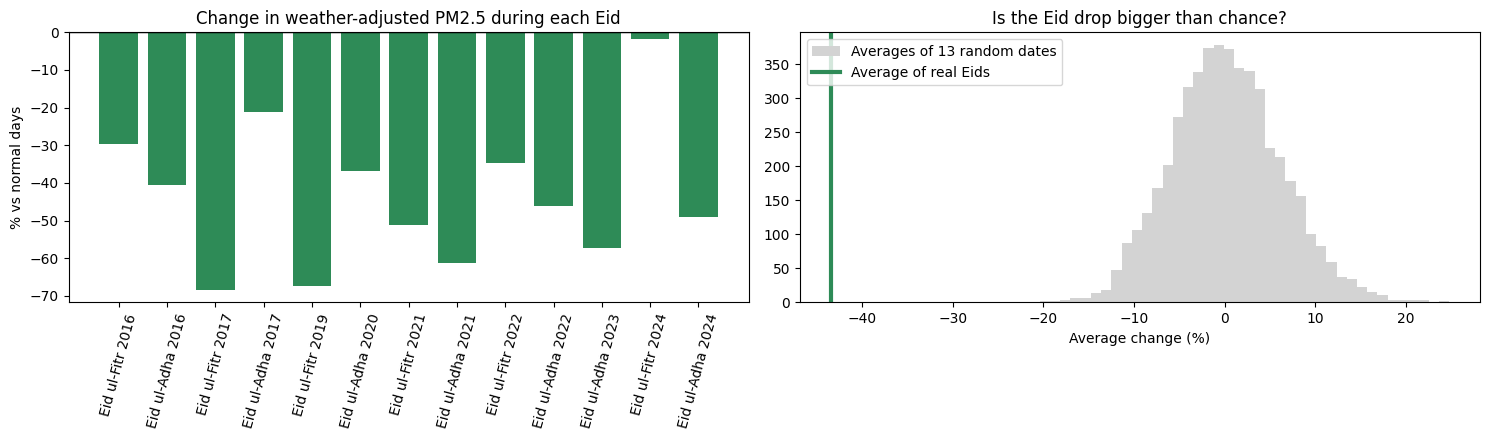

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
t = tested.sort_values("start_date")
ax[0].bar(t["event"], t["effect"], color="seagreen")
ax[0].axhline(0, color="black", lw=1)
ax[0].set_title("Change in weather-adjusted PM2.5 during each Eid")
ax[0].set_ylabel("% vs normal days"); ax[0].tick_params(axis="x", rotation=75)
ax[1].hist(fake_averages, bins=40, color="lightgrey", label=f"Averages of {n} random dates")
ax[1].axvline(tested["effect"].mean(), color="seagreen", lw=3, label="Average of real Eids")
ax[1].set_title("Is the Eid drop bigger than chance?")
ax[1].set_xlabel("Average change (%)"); ax[1].legend()
plt.tight_layout(); plt.show()

In [5]:
s = d["adjusted_pct"]
during = s.loc["2020-03-26":"2020-05-30"]
normal = pd.concat([s.loc["2020-02-01":"2020-03-07"], s.loc["2020-06-15":"2020-07-15"]])
print("COVID holiday effect:", round(during.mean() - normal.mean(), 1), "%  (days:", len(during), "vs", len(normal), ")")

COVID holiday effect: -19.7 %  (days: 42 vs 53 )


In [6]:
print("Smallest average effect we could reliably detect across 12 events: about",
      round(2 * fake.std() / np.sqrt(12), 1), "%")

Smallest average effect we could reliably detect across 12 events: about 12.6 %
